# 02 · Preprocessing check and first baselines — FD001

**Goal.** Exercise the step-3 pipeline (`src/features.py`) end to end and get the first point
predictions (step 4): `LinearRegression` and an untuned `LGBMRegressor`.

**Protocol (never broken).** Engines are split 70 / 15 / 15 into train / calibration / internal test
with `GroupShuffleSplit(groups = unit)`; the feature pipeline (regimes, scalers, constant-sensor
detection) is fitted on the 70 % training engines only; the label is capped at `RUL_CAP = 125`; the
official `test_FD001.txt` is scored at the last cycle of each engine against `RUL_FD001.txt`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import SEED, RUL_CAP
from src.experiment import prepare, fit_point_models, evaluate_point, log_official
from src.results import load_runs
from src.plots import save

pd.set_option("display.width", 160)
pd.set_option("display.precision", 3)

## Step 3 — preprocessing check

In [2]:
data = prepare("FD001", seed=SEED)
print("engines per set :", {k: len(v) for k, v in data.units.items()})
print("dropped sensors :", data.pipeline.dropped_sensors_)
names = data.pipeline.feature_names
print(len(names), "features:", names[:3], "...", names[-2:])
data.describe()

engines per set : {'train': 70, 'cal': 15, 'test': 15}
dropped sensors : ['s_1', 's_5', 's_6', 's_10', 's_16', 's_18', 's_19']
42 features: ['s_2', 's_3', 's_4'] ... ['s_20_rs10', 's_21_rs10']


,engines,rows,features
train,70,14290,42
cal,15,2909,42
test,15,3432,42
official,100,100,42


70 / 15 / 15 engines give ≈14 k / 3 k / 3 k rows; the official set contributes exactly one row per
test engine. The 14 kept sensors become 42 features (value, 10-cycle rolling mean, rolling std).

In [3]:
kept = data.pipeline.kept_sensors_
scale_check = pd.DataFrame({
    "train mean": data.X("train")[kept].mean(), "train std": data.X("train")[kept].std(),
    "cal mean": data.X("cal")[kept].mean(), "cal std": data.X("cal")[kept].std(),
    "official mean": data.X("official")[kept].mean(), "official std": data.X("official")[kept].std(),
})
scale_check.round(2)

,train mean,train std,cal mean,cal std,official mean,official std
s_2,0.0,1.0,-0.04,0.97,0.16,0.88
s_3,-0.0,1.0,0.00,0.99,0.21,1.08
s_4,-0.0,1.0,-0.06,0.97,0.17,0.95
s_7,0.0,1.0,0.07,0.98,-0.23,0.99
s_8,-0.0,1.0,-0.12,0.99,0.29,0.90
s_9,-0.0,1.0,0.22,1.25,-0.05,1.03
s_11,-0.0,1.0,-0.06,0.96,0.19,0.96
s_12,-0.0,1.0,0.08,0.95,-0.17,0.93
s_13,-0.0,1.0,-0.11,0.98,0.27,0.93
s_14,0.0,1.0,0.22,1.25,-0.05,1.00


The training engines are centred and scaled exactly (mean 0, std 1); the calibration engines only
approximately, because the statistics came from the training engines alone. The official last-cycle
rows sit systematically away from 0 — they are closer to failure than an average training row.

share of training rows saturated at 125: 38.8%
official test engines with RUL >= 125: 11 of 100


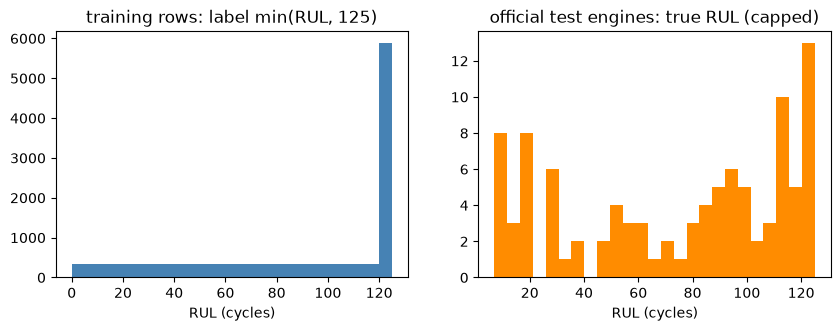

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(data.y("train"), bins=25, color="steelblue")
axes[0].set(title=f"training rows: label min(RUL, {RUL_CAP})", xlabel="RUL (cycles)")
axes[1].hist(data.y("official"), bins=25, color="darkorange")
axes[1].set(title="official test engines: true RUL (capped)", xlabel="RUL (cycles)")
save(fig, "baselines_fd001_label_distribution.png")
print(f"share of training rows saturated at {RUL_CAP}: {(data.y('train') == RUL_CAP).mean():.1%}")
print(f"official test engines with RUL >= {RUL_CAP}: {(data.y('official') >= RUL_CAP).sum()} of {len(data.y('official'))}")

**Interpretation.** About 40 % of the training rows sit at the cap, while the official test engines are
spread between 7 and 125 with a median near 86. Calibration rows (drawn like training rows) and
official-test rows therefore do not follow the same RUL distribution — keep this in mind when reading
the conformal coverage in notebook 03.

## Step 4 — baselines

In [5]:
models = fit_point_models(data, seed=SEED)
table = evaluate_point(models, data)
table.pivot(index="model", columns="eval_set", values=["rmse", "nasa_score"]).round(2)

rmse        nasa_score          
eval_set official   test   official      test
model                                        
lgbm        19.21  18.05    1387.64  31960.08
linear      20.90  20.45    1712.89  22584.46

**Interpretation.** Untuned LightGBM beats the linear floor on RMSE on both evaluation sets
(official ≈ 19 vs ≈ 21 cycles) and lands at the upper edge of the 16–19 band expected for classical
ML on FD001. The NASA score of the internal test is a sum over ≈3 400 rows and the official one over
100 engines, so the two columns are not comparable in size — only across models.

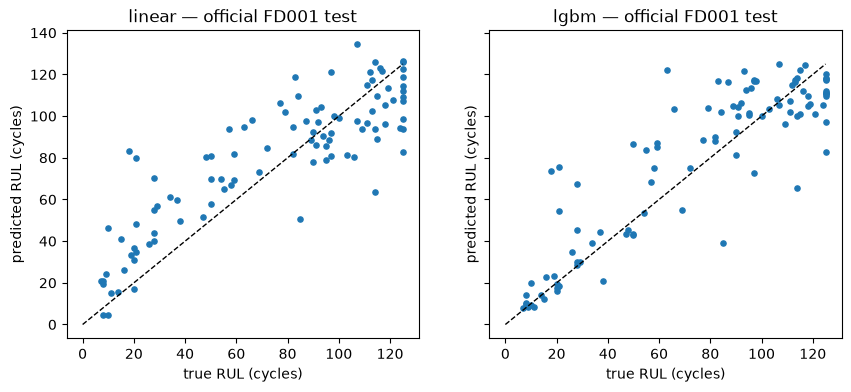

In [6]:
y_off = data.y("official")
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (name, model) in zip(axes, models.items()):
    ax.scatter(y_off, model.predict(data.X("official")), s=14)
    ax.plot([0, RUL_CAP], [0, RUL_CAP], "k--", lw=1)
    ax.set(title=f"{name} — official FD001 test", xlabel="true RUL (cycles)", ylabel="predicted RUL (cycles)")
save(fig, "baselines_fd001_pred_vs_true.png")

**Interpretation.** Both models track the diagonal well below ≈70 cycles and flatten above it: once an
engine shows no wear the model can only answer "healthy", which the cap turns into ≈125. The largest
errors are therefore early-life engines, not the ones close to failure — good news for maintenance,
and the reason the NASA score (which punishes late predictions) stays moderate.

In [7]:
gain = pd.Series(models["lgbm"].booster_.feature_importance("gain"), index=names)
(gain / gain.sum()).sort_values(ascending=False).head(10).round(3).rename("share of gain").to_frame()

,share of gain
s_4_rm10,0.273
s_11_rm10,0.198
s_15_rm10,0.113
s_2_rm10,0.081
s_9_rm10,0.070
s_3_rm10,0.033
s_14_rm10,0.029
s_21_rm10,0.024
s_17_rm10,0.020
s_9,0.017


The rolling means of the strongest EDA sensors (s_11, s_4, s_12, s_7, s_15) carry most of the split
gain — the smoothing added in step 3 is what the trees actually use.

In [8]:
# One row per (subset, model, seed) on the official test set -> results/runs.csv
log_official(table, "FD001", SEED)
load_runs()

,subset,model,seed,rmse,nasa_score,coverage,mean_width,n_test
0,FD001,linear,0,20.899,1712.89,NaN,NaN,100
1,FD001,lgbm,0,19.214,1387.64,NaN,NaN,100


Logged: `linear` and `lgbm` for seed 0 (coverage and width stay empty for point models). Notebook 03
adds the conformal rows.